# Synthetic light curves: from known signals to recovery

In [1]:
%matplotlib inline

# Import analysis, plotting, and output-path tools and record the version.
import os
from pathlib import Path
import matplotlib.pyplot as plt
import nahiku
from nahiku import Nahiku
print(f"Nāhiku {nahiku.__version__}")

# Set the display resolution and simplify plot borders.
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

/tmp/nahiku-02/lib/python3.12/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Nāhiku 0.2.0


## 1. Generate variability, inject dips, and prewhiten

This CPU example runs offline and uses known simulation labels. Generate a two-day sinusoid with Gaussian measurement noise, then inject a symmetric Gaussian dip and an asymmetric exocomet profile. Remove coherent periodic variability with Balmung before standardization and GP fitting. Prewhitening uses all observations without an injection mask and can absorb some dip signal; recovery is evaluated against the original injection labels. Standardization rescales uncertainties with flux.

In [2]:
# Generate reproducible sinusoidal variability with white measurement noise.
lc = Nahiku.from_synthetic_noise(duration=10, n_points=200, period=2,
                                 amplitude=0.3, white_noise=0.02, red_noise=0, seed=48)

# Inject two dip profiles and retain their truth labels for evaluation.
lc.inject_anomaly(center=4.8, width=0.12, depth=0.8, shape="gaussian")
lc.inject_anomaly(center=7.4, width=0.07, depth=0.45, shape="exocomet")

# Remove significant periodic components using Balmung before fitting the GP.
prewhitening = lc.prewhiten(
    method="balmung", fmin=0.1, fmax=2, max_components=3, minimum_snr=4,
)
print("Removed frequencies [cycles/day]:", prewhitening.frequencies)

# Standardize the residual light curve and fit the shared GP.
lc.standardize()
lc.fit_gp(period=2, length_scale=4, iterations=120)

  0%|          | 0/3 [00:00<?, ?it/s]

 33%|███▎      | 1/3 [00:00<00:00, 279.21it/s]

Removed frequencies [cycles/day]: [0.49662541]


GP stopping reason: iteration_limit


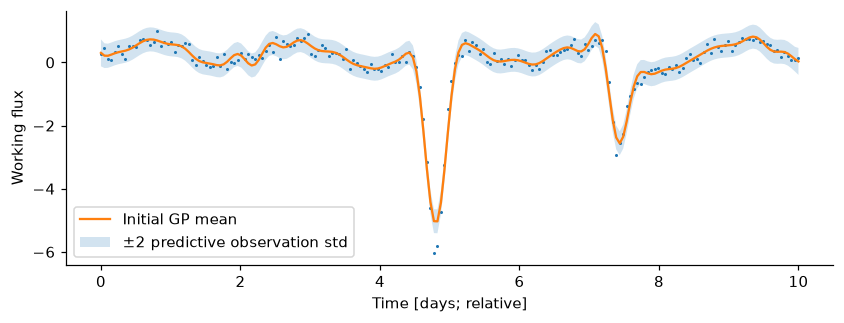

In [3]:
# Inspect the shared GP fit before excluding any detected intervals.
mean, std = lc.predict(include_noise=True)
fig, ax = lc.plot()
ax.plot(lc.time, mean, label="Initial GP mean")
ax.fill_between(lc.time, mean - 2*std, mean + 2*std,
                alpha=0.2, label="±2 predictive observation std")
ax.legend();
print("GP stopping reason:", lc.fit_diagnostics["stopping_reason"])

## 2. Compare independent searches

Greedy detection starts from ordinary posterior residuals and grows intervals while the retained-data marginal log likelihood (MLL) metric improves. Both searches use Torch conditioning by default. Exhaustive detection tests bounded intervals against a conditional multivariate prediction. Its p-values are nominal: overlapping tests and fitted hyperparameters mean the threshold is not a calibrated survey-wide false-positive rate.

Greedy: {'matched_events': 2, 'detected_events': 2, 'true_events': 2, 'false_positives': 0, 'missed_events': 0, 'precision': 1.0, 'recall': 1.0}
Exhaustive: {'matched_events': 2, 'detected_events': 2, 'true_events': 2, 'false_positives': 0, 'missed_events': 0, 'precision': 1.0, 'recall': 1.0}


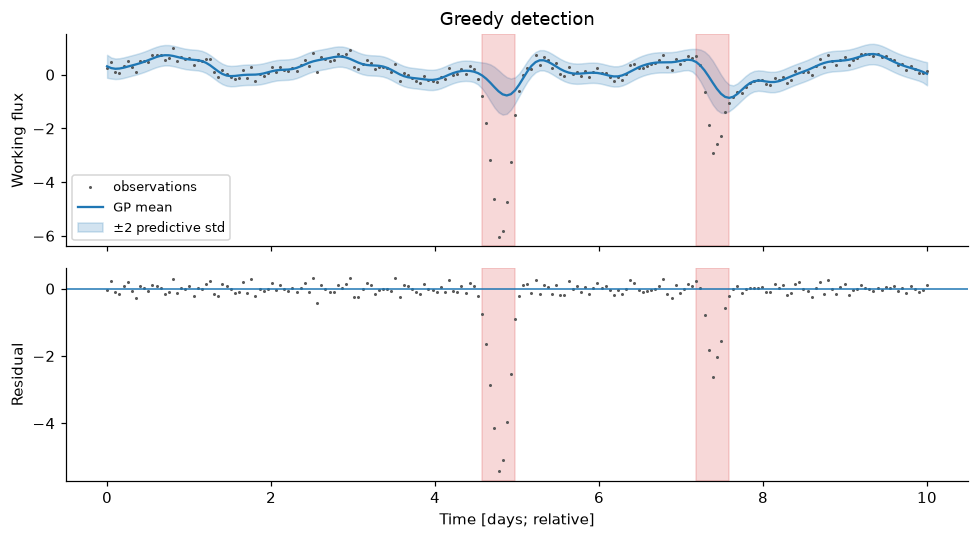

In [4]:
# Seed greedy detection from posterior residuals and grow while MLL improves.
greedy = lc.greedy_search(
    sigma=3, seed_statistic="residual", len_deviant=1,
    growth="metric", growth_metric="mll", direction="negative",
)

# Score candidate intervals independently using conditional p-values.
exhaustive = lc.exhaustive_search(min_points=3, max_points=16, step=3,
                                size_step=3, threshold=1e-8)

# Inspect greedy predictions and residuals after excluding its detected intervals.
greedy.plot();

# Measure event recovery against the original injected truth labels.
print("Greedy:", lc.evaluate(greedy))
print("Exhaustive:", lc.evaluate(exhaustive))

Event matching is one-to-one. A single broad detection cannot count as two correct detections. Injection truth extends to 1% of each profile’s peak; detection boundaries need not match that support exactly.

The upper panel shows the GP prediction conditioned on observations outside all detected intervals. In the lower panel, each colored curve excludes only its own candidate window. Matching dots identify the excluded observations, and bands show ±2 predictive observation standard deviations. By default, each merged event is represented by its strongest selected candidate, with ties resolved by sample bounds. Use `selection="all"` to show all selected windows, including overlaps. A merged event may span several scored windows. Joint scores use correlations between observations as well as the pointwise uncertainties shown in the bands.

`event_index` selects a merged event by its zero-based index and plots its representative candidate's GP across the full light curve. Other detections remain in the conditioning data. The stored predictions include any candidate-specific refits, so plotting requires no further optimization or live GP. Use `kind="residuals"` to inspect residuals after excluding all detected intervals. Numerical exports include the conditional distributions.

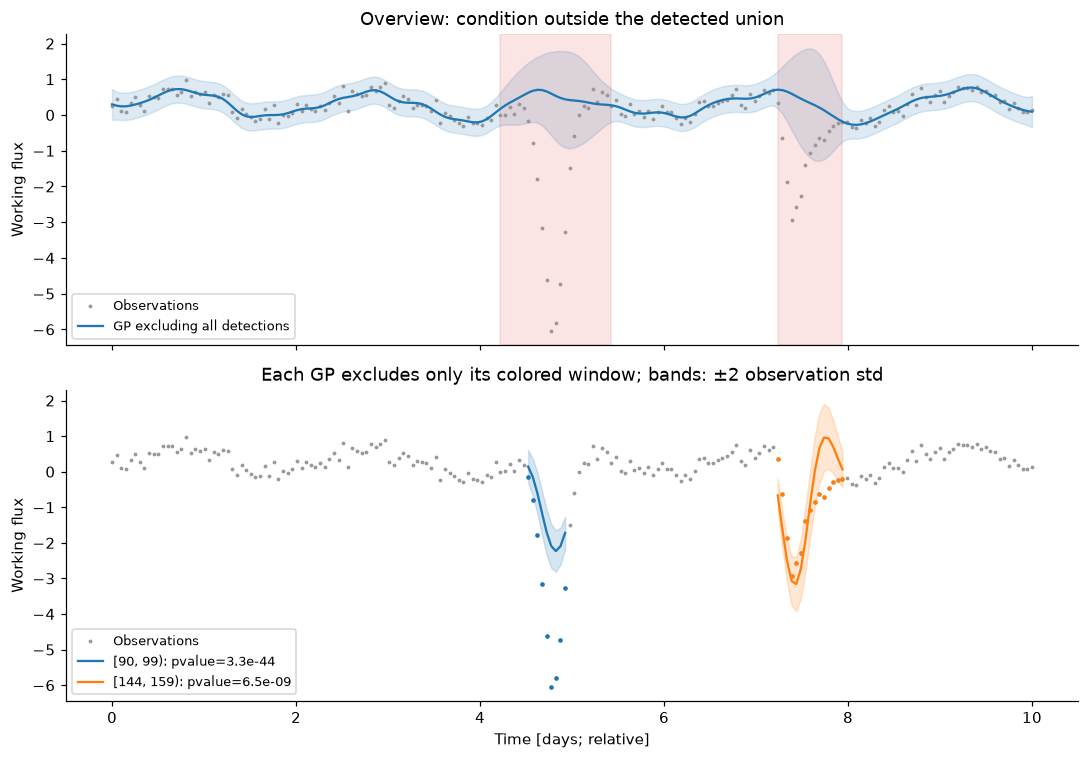

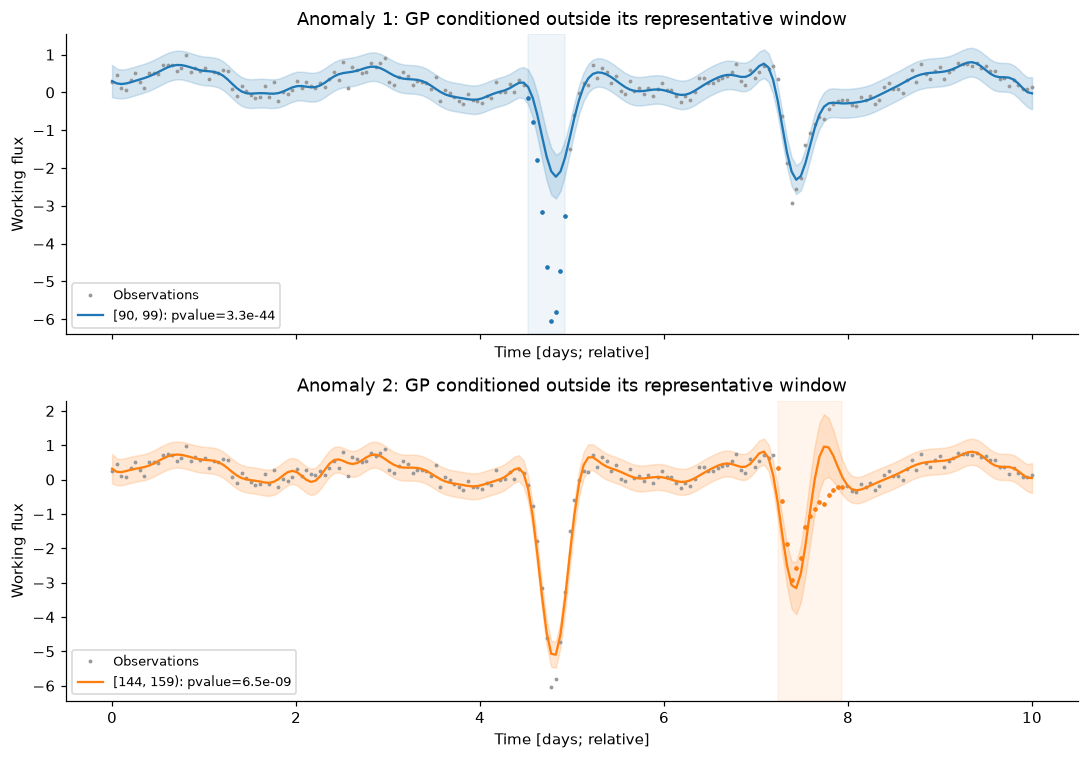

In [5]:
# Inspect the scored conditional fit for one representative window per event.
exhaustive.plot(kind="conditional");

# Show each anomaly's conditional GP over the full light curve in its own panel.
if exhaustive.intervals:
    fig, axes = plt.subplots(len(exhaustive.intervals), 1, figsize=(10, 7),
                             sharex=True, squeeze=False)
    for event_index, ax in enumerate(axes[:, 0]):
        exhaustive.plot(axes=ax, kind="conditional", event_index=event_index)
        ax.set_title(f"Anomaly {event_index + 1}: GP conditioned outside its representative window")
    fig.tight_layout();

# All overlapping selected windows remain accessible with selection="all".
# exhaustive.plot(kind="conditional", selection="all");

## 3. Sample correlated variability directly from a GP

The second generator draws a stochastic quasi-periodic function, rather than adding an explicit sinusoid and Ornstein–Uhlenbeck (OU) noise. The same seed reproduces the draw without changing NumPy’s global random state.

{'matched_events': 1, 'detected_events': 1, 'true_events': 1, 'false_positives': 0, 'missed_events': 0, 'precision': 1.0, 'recall': 1.0}


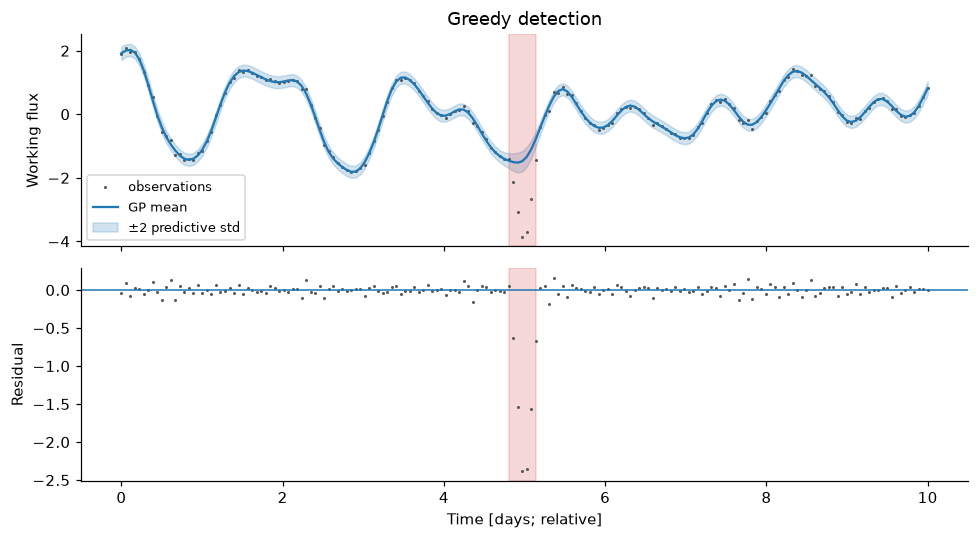

In [6]:
# Draw stochastic quasi-periodic variability directly from a GP.
gp_lc = Nahiku.from_synthetic_gp(duration=10, n_points=180, period=2,
                                  amplitude=0.3, length_scale=4, white_noise=0.02, seed=17)

# Inject a triangular dip into the GP realization.
gp_lc.inject_anomaly(center=5, width=0.18, depth=0.8, shape="saw")

# Fit this correlated light curve directly, without sinusoidal prewhitening.
gp_lc.standardize().fit_gp(period=2, length_scale=4, iterations=100)

# Detect the dip with posterior-residual seeds and MLL-based interval growth.
gp_result = gp_lc.greedy_search(
    sigma=3, seed_statistic="residual", len_deviant=1,
    growth="metric", growth_metric="mll", direction="negative",
)

# Inspect the prediction and evaluate one-to-one event recovery.
gp_result.plot();
print(gp_lc.evaluate(gp_result))

## 4. Export portable numerical results

Exports contain predictions, residuals, detection masks, candidate scores, configuration, and software version. They contain numerical data and metadata rather than a pickled model.

In [7]:
# Choose a configurable output directory for persistent numerical exports.
output = Path(os.environ.get("NAHIKU_OUTPUT", "outputs"))

# Save the first experiment's search snapshots and observation lineage.
greedy.export(output / "synthetic_greedy")
exhaustive.export(output / "synthetic_exhaustive")
lc.export(output / "synthetic_lightcurve")
print("Saved results to", output)

Saved results to /tmp/nahiku-orange-example


## Interpret the result

The first experiment removes coherent sinusoidal variability with Balmung before fitting a GP and running both searches. The second draws correlated variability from a GP and fits it directly. Both greedy calls seed detections from posterior residuals and grow intervals using the retained-data marginal log likelihood (MLL) metric, with a fixed residual threshold. Exhaustive search scores candidate windows independently.

Both searches recover the two injected events in the prewhitened experiment without additional detections. Greedy search recovers the triangular dip in the GP-generated experiment without additional detections. The initial GP in the first experiment reaches its iteration limit; this stopping reason does not establish optimizer convergence.

Injection labels provide event-level truth for these simulations. Recovery does not establish accurate dip boundaries or preservation of depth after prewhitening. Thresholds are not calibrated survey-wide false-alarm probabilities. These reproducible examples do not provide a complete sensitivity benchmark. Performance depends on noise, cadence, profile widths, and kernel assumptions.

Consult the API reference for parameter and return-value details.